# Problem 2 · Phosphorus diffusion into silicon

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *A silicon wafer is doped with phosphorus in a chemical vapour deposition (CVD) reactor at 1100 °C. The phosphorus concentration at the wafer surface is held at $c_{As} = 2.5\times10^{20}$ atoms/cm³ and the wafer initially contains no phosphorus. The diffusivity of P in Si is $D_{AB} = 6.5\times10^{-13}$ cm²/s. Predict the concentration profile of P atoms after 1 h, and the depth of the Si–P thin film, defined as the depth where the concentration has fallen to 1 % of the surface value ($2.5\times10^{18}$ atoms/cm³).*

Problem 1 was **steady**: the temperature did not change in time. This problem is **unsteady** (transient): the phosphorus slowly creeps into the wafer, so the concentration depends on both depth $z$ and time $t$. We will **march forward in time** with the finite difference method, again following **the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the doping process and collect the data |
| 2 · Grid | divide depth *and* time into small steps; cut the "infinite" wafer at a safe depth |
| 3 · Physics | derive Fick's second law, the diffusion equation |
| 4 · Numerical scheme | the explicit FTCS scheme: forward in time, centred in space |
| 5 · Solution setup | choose the time step so that the scheme is stable |
| 6 · Compute | march 100 time steps through one hour |
| 7 · Post-processing | profiles, the film depth, comparison with the exact solution, grid check |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only import used in the calculations is `math` (part of Python itself), for the error function `erf` in the exact solution. The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: sqrt, erf
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

To make a semiconductor conduct electricity in a controlled way, we add tiny amounts of other atoms to the silicon: **doping**. In this process, phosphorus oxychloride (POCl₃) vapour is fed into a CVD reactor where it reacts on the silicon surface:

$$\mathrm{Si(s)} + 2\,\mathrm{POCl_3(g)} \;\longrightarrow\; \mathrm{SiO_2(s)} + 3\,\mathrm{Cl_2(g)} + 2\,\mathrm{P(s)}$$

A thin **SiO₂ coating rich in phosphorus** forms on the surface. It is the **source** of phosphorus. The P atoms then **diffuse into the crystalline silicon**, which acts as a **sink**, and form a thin Si–P film. The concentration profile of P controls the electrical conductivity of that film, so engineers need to predict it.

Because the diffusivity of P in solid silicon is extremely small, the phosphorus only penetrates a few micrometres in an hour, a tiny distance compared with the wafer thickness (hundreds of micrometres). The phosphorus never "sees" the back of the wafer, so we can treat the wafer as **semi-infinite**: it starts at the surface $z = 0$ and extends to $z \to \infty$.

| Quantity | Symbol | Value |
|---|:-:|---|
| process temperature | $T$ | 1100 °C |
| surface concentration of P (constant) | $c_{As}$ | $2.5\times10^{20}$ atoms/cm³ |
| initial concentration of P in the wafer | $c_{A0}$ | 0 |
| diffusivity of P in Si at 1100 °C | $D_{AB}$ | $6.5\times10^{-13}$ cm²/s |
| doping time | $t$ | 1 h = 3600 s |
| film edge: target concentration (1 % of $c_{As}$) | $c_A$ | $2.5\times10^{18}$ atoms/cm³ |

**Assumptions:**

* unsteady state;
* semi-infinite medium;
* one-dimensional diffusion in the $z$-direction;
* constant boundary conditions ($c_{A0}$ and $c_{As}$ do not change);
* constant temperature and pressure, and constant diffusivity;
* the P-rich coating is an *infinite source*: it never runs out, so $c_{As}$ stays constant;
* phosphorus is dilute in the silicon, so Fick's law with a constant $D_{AB}$ applies.

In [2]:
# ---- process data ---------------------------------------------------------
T_process = 1100.0    # process temperature                  [°C]
c_As = 2.5e20         # surface concentration of P            [atoms/cm^3]
c_A0 = 0.0            # initial concentration of P in the wafer [atoms/cm^3]
D_cm2 = 6.5e-13       # diffusivity of P in Si at 1100 °C     [cm^2/s]
t_end = 3600.0        # doping time: 1 hour                   [s]
target = 0.01         # film edge: c_A = 1 % of the surface value

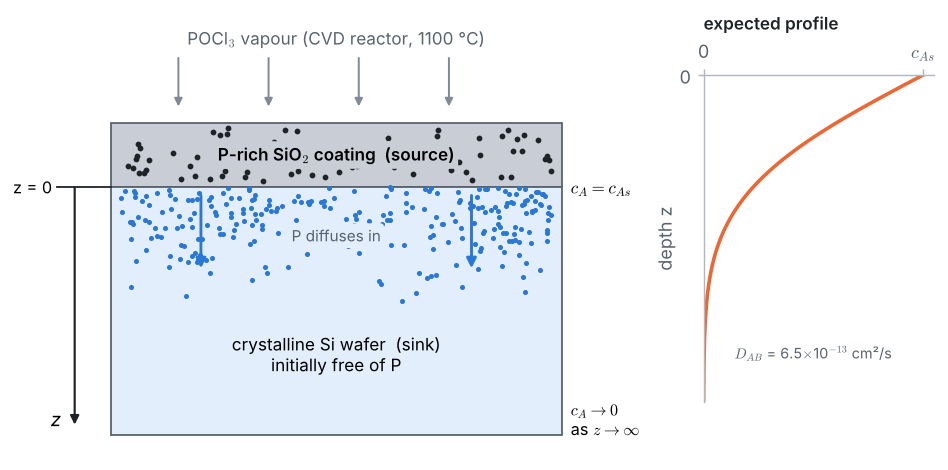

In [3]:
plots.schematic(c_As, D_cm2, T_process)

**Choosing convenient units.** Distances of a few micrometres expressed in centimetres give awkward numbers like $10^{-4}$, so we work in **micrometres (µm) and seconds**. Since $1\ \text{cm} = 10^4\ \text{µm}$, we have $1\ \text{cm}^2 = 10^8\ \text{µm}^2$.

A useful yardstick for any diffusion problem is the **diffusion length** $\sqrt{D t}$: roughly how far the atoms travel in a time $t$.

In [4]:
D = D_cm2 * 1e8                    # diffusivity in µm^2/s

diffusion_length = math.sqrt(D * t_end)
print(f"D = {D:.2e} µm^2/s")
print(f"diffusion length after 1 h:  sqrt(D t) = {diffusion_length:.3f} µm")

D = 6.50e-05 µm^2/s
diffusion length after 1 h:  sqrt(D t) = 0.484 µm


Half a micrometre in an hour: diffusion in solids is slow!

---
## Pillar 2 · The grid in space *and* time

**Space.** The wafer is semi-infinite, but a computer can only handle a finite number of nodes, so we must stop the grid at some depth $z_{max}$. We choose $z_{max}$ so deep that the phosphorus cannot get there in one hour. Five micrometres is about **ten diffusion lengths**; we will check later that the concentration there is still practically zero, so replacing "$c_A \to 0$ as $z \to \infty$" by "$c_A = 0$ at $z = z_{max}$" changes nothing.

$$z_i = i\,\Delta z, \qquad i = 0, 1, \dots, N, \qquad \Delta z = \frac{z_{max}}{N}.$$

**Time.** We also cut time into steps of size $\Delta t$ and compute the concentration only at the times $t^n = n\,\Delta t$, $n = 0, 1, 2, \dots$ The unknowns are therefore $C_i^n$: the concentration at node $i$ and time level $n$.

In [5]:
z_max = 5.0               # depth where we cut the semi-infinite wafer [µm]
dz = 0.1                  # grid spacing                               [µm]
N = round(z_max / dz)     # number of intervals

z = []                    # depth of every node [µm]
for i in range(N + 1):
    z.append(i * dz)

print(f"N = {N} intervals, dz = {dz} µm, {len(z)} nodes from z = 0 to z = {z[-1]:.1f} µm")
print(f"z_max = {z_max / diffusion_length:.1f} diffusion lengths")

N = 50 intervals, dz = 0.1 µm, 51 nodes from z = 0 to z = 5.0 µm
z_max = 10.3 diffusion lengths


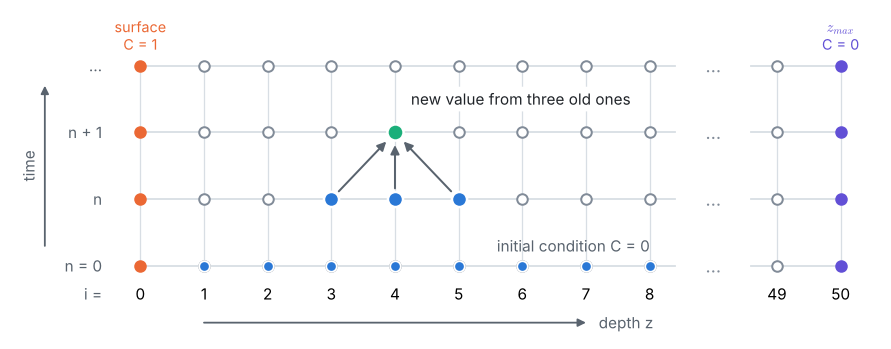

In [6]:
plots.grid(N)

Each column is a node at a fixed depth, each row a moment in time. The bottom row ($n = 0$) is the **initial condition**, the left column is the **surface** (concentration known), the right column is the **cut** at $z_{max}$ (concentration zero). The arrows show the idea of the explicit scheme of Pillar 4: a new value is computed from three values of the previous time level.

---
## Pillar 3 · Physics: the diffusion equation

Take a thin slice of the wafer between $z$ and $z + dz$ (area $A$). A **mass balance** for phosphorus says:

$$\underbrace{\frac{\partial c_A}{\partial t}\,A\,dz}_{\text{accumulation}} \;=\; \underbrace{J_z A}_{\text{in}} \;-\; \underbrace{J_{z+dz}A}_{\text{out}} \;=\; -\frac{\partial J_z}{\partial z}\,A\,dz .$$

**Fick's first law** relates the diffusion flux to the concentration gradient: atoms move from high to low concentration,

$$J_z = -D_{AB}\,\frac{\partial c_A}{\partial z}.$$

Together they give **Fick's second law**, the one-dimensional **diffusion equation** (the continuity equation for species A reduces to it here):

$$\frac{\partial c_A}{\partial t} = D_{AB}\,\frac{\partial^2 c_A}{\partial z^2}.$$

It is first order in time, so it needs **one initial condition**, and second order in space, so it needs **two boundary conditions**:

| | condition | meaning |
|---|---|---|
| initial condition | $c_A(z, 0) = c_{A0} = 0$ | the wafer starts free of phosphorus |
| boundary condition at the surface | $c_A(0, t) = c_{As}$ | the coating keeps the surface concentration constant |
| boundary condition deep inside | $c_A(\infty, t) = c_{A0} = 0$ | far away, the wafer is untouched |

**Dimensionless concentration.** Concentrations of order $10^{20}$ are clumsy. Dividing by the surface value gives

$$C = \frac{c_A - c_{A0}}{c_{As} - c_{A0}} = \frac{c_A}{c_{As}}, \qquad \frac{\partial C}{\partial t} = D\,\frac{\partial^2 C}{\partial z^2}, \qquad C(z,0) = 0,\quad C(0,t) = 1,\quad C(\infty,t) = 0,$$

so $C$ goes from 1 at the surface to 0 deep inside, and the film edge is where $C = 0.01$.

**Exact solution.** For a semi-infinite medium this problem has a famous analytical solution, built with the *error function* $\mathrm{erf}$:

$$\frac{c_{As} - c_A}{c_{As} - c_{A0}} = \mathrm{erf}\!\left(\frac{z}{2\sqrt{D_{AB}\,t}}\right)
\qquad\Longleftrightarrow\qquad
C(z,t) = 1 - \mathrm{erf}\!\left(\frac{z}{2\sqrt{D t}}\right).$$

At the film edge $c_A = 2.5\times10^{18}$, so $\mathrm{erf}(\eta) = (2.5\times10^{20} - 2.5\times10^{18})/2.5\times10^{20} = 0.99$, where $\eta = z/(2\sqrt{Dt})$. Erf tables give $\eta \approx 1.82$. Below we find $\eta$ more precisely with a few lines of Python (the **bisection method**: keep halving an interval that contains the answer).

In [7]:
def C_exact(zz, t):
    """Exact dimensionless concentration c_A/c_As at depth zz [µm] and time t [s]."""
    return 1.0 - math.erf(zz / (2.0 * math.sqrt(D * t)))


# solve erf(eta) = 1 - target = 0.99 by bisection
low, high = 0.0, 5.0
for _ in range(60):
    eta = 0.5 * (low + high)
    if math.erf(eta) < 1.0 - target:
        low = eta          # erf still too small: the answer is to the right
    else:
        high = eta         # erf too large: the answer is to the left


def depth_exact(t):
    """Exact depth [µm] where c_A = 1 % of c_As after a time t [s]."""
    return 2.0 * eta * math.sqrt(D * t)


print(f"erf(eta) = 0.99  ->  eta = {eta:.4f}")
print(f"exact film depth after 1 h:  z = 2 eta sqrt(D t) = {depth_exact(t_end):.4f} µm")

erf(eta) = 0.99  ->  eta = 1.8214
exact film depth after 1 h:  z = 2 eta sqrt(D t) = 1.7621 µm


So the exact answer is about **1.76 µm**. Of course, real problems rarely have an exact solution; here it lets us check that our finite difference code works.

---
## Pillar 4 · Numerical scheme: the explicit FTCS scheme

We need two derivatives at node $i$ and time level $n$:

* **time:** a **forward** difference (from $t^n$ to $t^{n+1}$), error $\mathcal{O}(\Delta t)$
$$\frac{\partial C}{\partial t}\bigg|_i^n \approx \frac{C_i^{n+1} - C_i^n}{\Delta t}$$
* **space:** a **central** difference at the *old* time level, error $\mathcal{O}(\Delta z^2)$
$$\frac{\partial^2 C}{\partial z^2}\bigg|_i^n \approx \frac{C_{i-1}^n - 2C_i^n + C_{i+1}^n}{\Delta z^2}$$

Putting both into the diffusion equation and solving for the only unknown, $C_i^{n+1}$:

$$\boxed{\,C_i^{n+1} = C_i^n + r\left(C_{i-1}^n - 2C_i^n + C_{i+1}^n\right), \qquad r = \frac{D\,\Delta t}{\Delta z^2}\,}$$

This is the **FTCS** scheme (*Forward in Time, Centred in Space*). It is **explicit**: every new value comes directly from three known values of the previous time level, so there is **no system of equations to solve**, just a loop.

The boundary nodes are not computed with this formula; their values are imposed at every time level:

$$C_0^{n+1} = 1 \quad\text{(surface)}, \qquad C_N^{n+1} = 0 \quad\text{(cut at } z_{max}).$$

In [8]:
def ftcs_step(C_old, r):
    """Advance the concentration one time step with the explicit FTCS scheme."""
    n_nodes = len(C_old)
    C_new = [0.0] * n_nodes

    C_new[0] = 1.0                 # surface: c_A = c_As at all times
    for i in range(1, n_nodes - 1):
        C_new[i] = C_old[i] + r * (C_old[i - 1] - 2.0 * C_old[i] + C_old[i + 1])
    C_new[n_nodes - 1] = 0.0       # deep inside: no phosphorus

    return C_new

Notice that we write the new values into a **new list** `C_new` and only read from `C_old`. If we overwrote `C_old` while looping, node $i$ would use the already-updated value of node $i-1$, which is a different scheme.

---
## Pillar 5 · Solution setup: choosing a stable time step

A smaller $\Delta t$ means more steps (more work), a larger $\Delta t$ fewer steps. But the explicit scheme does not allow just any time step. Rewrite the update as

$$C_i^{n+1} = r\,C_{i-1}^n + (1 - 2r)\,C_i^n + r\,C_{i+1}^n .$$

The new value is a **weighted average** of the three old values (the weights $r$, $1 - 2r$, $r$ add up to 1). As long as all weights are positive, the new value always lies between its neighbours: no overshoot, no wiggles. The middle weight stays positive only if

$$\boxed{\,r = \frac{D\,\Delta t}{\Delta z^2} \le \frac{1}{2}\,} \qquad\Longleftrightarrow\qquad \Delta t \le \frac{\Delta z^2}{2D}.$$

This is the **stability condition** of FTCS. Break it and small errors are amplified at every step until the solution explodes (we will see this at the end). We pick a time step well inside the limit that also divides one hour into a round number of steps.

In [9]:
dt_max = dz**2 / (2.0 * D)        # largest stable time step [s]
dt = 36.0                         # our choice [s]
r = D * dt / dz**2                # must be <= 0.5
n_steps = round(t_end / dt)

print(f"stability limit: dt <= {dt_max:.1f} s")
print(f"chosen: dt = {dt:.0f} s  ->  r = {r:.3f}  (stable, since r <= 0.5)")
print(f"number of time steps for 1 h: {n_steps}")

stability limit: dt <= 76.9 s
chosen: dt = 36 s  ->  r = 0.234  (stable, since r <= 0.5)
number of time steps for 1 h: 100


---
## Pillar 6 · Compute: march through one hour

Start from the initial condition (no phosphorus in the wafer, surface at $C = 1$) and apply `ftcs_step` 100 times. We keep the profile of every time level in `history` for post-processing.

In [10]:
C = [0.0] * (N + 1)        # initial condition: no phosphorus in the wafer ...
C[0] = 1.0                 # ... except at the surface, held at c_As
history = [C[:]]           # history[n] = concentration profile at time level n

for n in range(1, n_steps + 1):
    C = ftcs_step(C, r)
    history.append(C)

print(f"done: {n_steps} steps, t = {n_steps * dt / 60:.0f} min")
print(" z [µm]   c_A/c_As (FDM)   exact")
for zz in (0.0, 0.5, 1.0, 1.5, 2.0, 2.5):
    i = round(zz / dz)
    print(f"{zz:6.1f}    {history[-1][i]:.6f}       {C_exact(zz, t_end):.6f}")

done: 100 steps, t = 60 min
 z [µm]   c_A/c_As (FDM)   exact
   0.0    1.000000       1.000000
   0.5    0.466040       0.464851
   1.0    0.144645       0.143806
   1.5    0.028512       0.028333
   2.0    0.003454       0.003461
   2.5    0.000251       0.000258


Let us look at the profiles after 10, 20, 30 and 60 minutes:

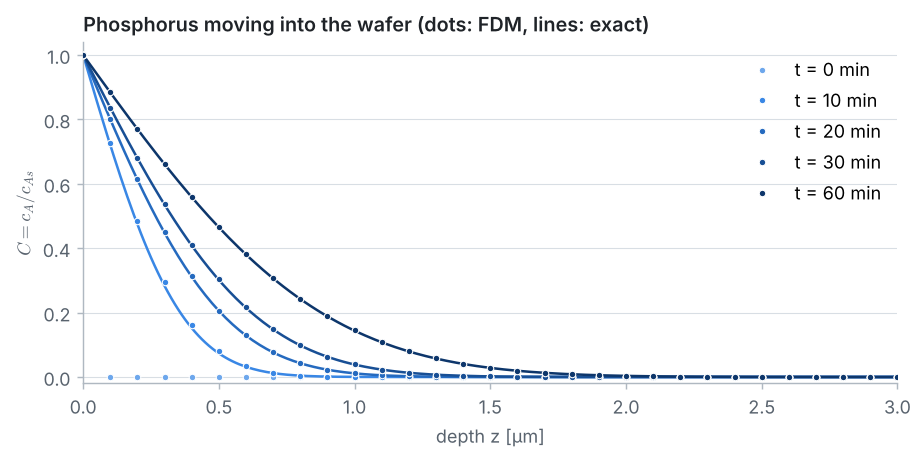

In [11]:
snapshots = {}
for minutes in (0, 10, 20, 30, 60):
    n = round(minutes * 60 / dt)
    snapshots[minutes * 60] = history[n]
plots.profiles(z, snapshots, C_exact)

The phosphorus front moves into the wafer, fast at first and then more and more slowly. The FDM dots lie on the exact curves at every time.

---
## Pillar 7 · Post-processing: the film depth, verification and stability

### Film depth after 1 h

The film edge is where the concentration falls to 1 % of the surface value, $C = 0.01$. This depth will almost never fall exactly on a node, so we find the two nodes on either side and draw a straight line between them (**linear interpolation**):

$$z_{film} = z_i + \frac{C_i - 0.01}{C_i - C_{i+1}}\,\Delta z, \qquad \text{where } C_i \ge 0.01 > C_{i+1}.$$

In [12]:
def film_depth(z, C, level):
    """Depth where the profile C first drops below 'level' (linear interpolation)."""
    for i in range(len(C) - 1):
        if C[i] >= level > C[i + 1]:
            return z[i] + (C[i] - level) / (C[i] - C[i + 1]) * (z[i + 1] - z[i])
    return 0.0                     # the level has not been reached anywhere yet


depth_fdm = film_depth(z, history[-1], target)
difference = 100 * (depth_fdm - depth_exact(t_end)) / depth_exact(t_end)
print(f"film depth after 1 h:  FDM {depth_fdm:.4f} µm    exact {depth_exact(t_end):.4f} µm"
      f"    ({difference:+.2f} %)")

film depth after 1 h:  FDM 1.7673 µm    exact 1.7621 µm    (+0.29 %)


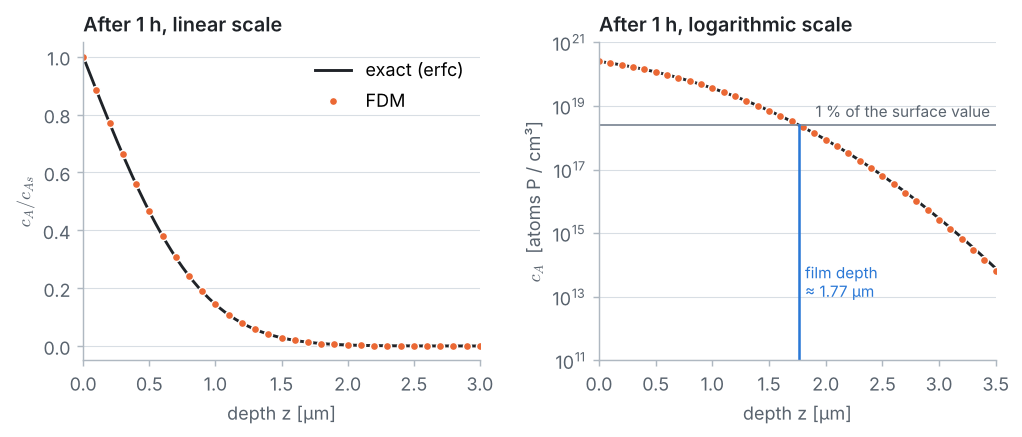

In [13]:
plots.compare(z, history[-1], C_exact, t_end, c_As, target, depth_fdm)

On the logarithmic scale (right) we can read the concentration over many orders of magnitude: it drops from $2.5\times10^{20}$ at the surface to $2.5\times10^{18}$ (1 %) at about 1.77 µm, and keeps falling very steeply below that.

### How does the film grow with time?

Apply `film_depth` to every stored time level:

In [14]:
times, depths = [], []
for n in range(1, n_steps + 1):
    times.append(n * dt)
    depths.append(film_depth(z, history[n], target))

for minutes in (15, 30, 60):
    n = round(minutes * 60 / dt)
    print(f"t = {minutes:2d} min:  FDM {depths[n - 1]:.3f} µm   exact {depth_exact(n * dt):.3f} µm")

t = 15 min:  FDM 0.887 µm   exact 0.881 µm
t = 30 min:  FDM 1.254 µm   exact 1.246 µm
t = 60 min:  FDM 1.767 µm   exact 1.762 µm


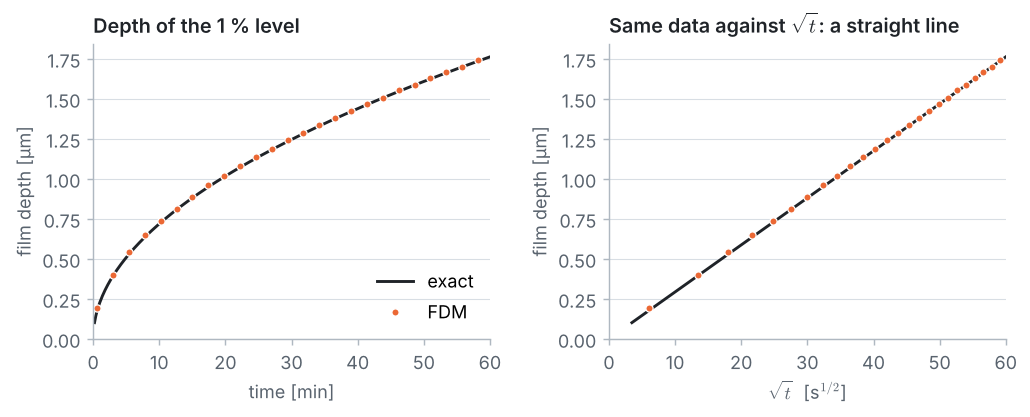

In [15]:
plots.depth_vs_time(times, depths, depth_exact)

The film depth grows like $\sqrt{t}$ (a straight line on the right): to make the film **twice as deep**, you need **four times as long**. This is the signature of every diffusion process. (In the very first steps the FDM depth jumps in steps of $\Delta z$, because the front has only crossed a couple of nodes.)

### Was $z_{max}$ deep enough?

If cutting the wafer at $z_{max}$ disturbed the solution, the concentration near the cut would not be negligible. Let us check the last nodes after one hour:

In [16]:
for i in (N - 20, N - 10, N - 1):
    print(f"z = {z[i]:.1f} µm:  c_A/c_As = {history[-1][i]:.1e}")

z = 3.0 µm:  c_A/c_As = 1.1e-05
z = 4.0 µm:  c_A/c_As = 3.5e-09
z = 4.9 µm:  c_A/c_As = 2.9e-13


Right next to the cut the concentration is about **$10^{-13}$ of the surface value**, far below anything that matters. The phosphorus never felt the cut, so our finite grid represents the semi-infinite wafer perfectly.

### Verification: refining the grid

FTCS has error $\mathcal{O}(\Delta t) + \mathcal{O}(\Delta z^2)$. If we halve $\Delta z$ **and keep $r$ fixed**, $\Delta t = r\,\Delta z^2/D$ drops by a factor of 4, so both error terms fall by 4. We re-run the whole calculation for several grids, using the same `ftcs_step` function:

In [17]:
def solve(dz, r):
    """Run the whole 1 h calculation on a grid with spacing dz at a fixed r."""
    N = round(z_max / dz)
    dt = r * dz**2 / D
    n_steps = round(t_end / dt)
    dt = t_end / n_steps                 # land exactly on t = 1 h
    C = [0.0] * (N + 1)
    C[0] = 1.0
    for n in range(n_steps):
        C = ftcs_step(C, D * dt / dz**2)
    return [i * dz for i in range(N + 1)], C, n_steps


dzs, errors = [], []
print(" dz [µm]   steps   largest error   ratio   film depth [µm]")
for dz_test in (0.2, 0.1, 0.05, 0.025):
    z_t, C_t, steps = solve(dz_test, r)
    error = max(abs(C_t[i] - C_exact(z_t[i], t_end)) for i in range(len(z_t)))
    ratio = f"{errors[-1] / error:5.2f}" if errors else "     "
    dzs.append(dz_test)
    errors.append(error)
    print(f"{dz_test:7.3f}   {steps:5d}   {error:.2e}        {ratio}    {film_depth(z_t, C_t, target):.4f}")

 dz [µm]   steps   largest error   ratio   film depth [µm]
  0.200      25   4.90e-03                 1.7750
  0.100     100   1.23e-03         3.98    1.7673
  0.050     400   3.08e-04         4.00    1.7632
  0.025    1600   7.69e-05         4.00    1.7625


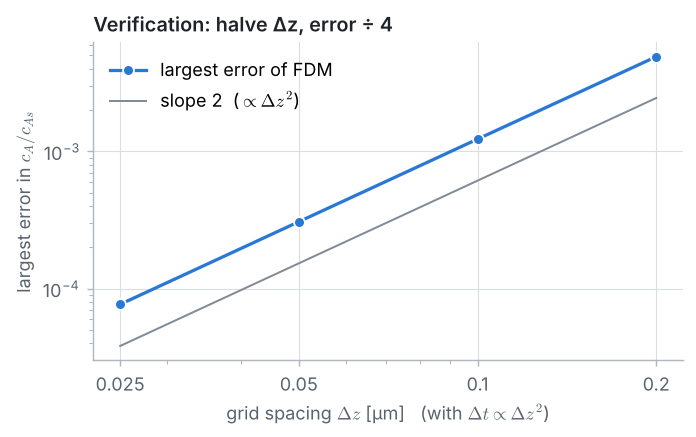

In [18]:
plots.convergence(dzs, errors)

Every halving of $\Delta z$ divides the error by 4, and the film depth converges to the exact 1.762 µm. Our grid ($\Delta z = 0.1$ µm) already gives the depth to within about 0.3 %.

### What if we ignore the stability limit?

Let us try a time step that is too large, $r = 0.6$ (that is, $\Delta t \approx 92$ s), and take a few steps:

In [19]:
r_bad = 0.6
C_bad = [0.0] * (N + 1)
C_bad[0] = 1.0
unstable_snapshots = {}
for n in range(1, 21):
    C_bad = ftcs_step(C_bad, r_bad)
    if n in (5, 10, 15, 20):
        unstable_snapshots[n] = C_bad[:]

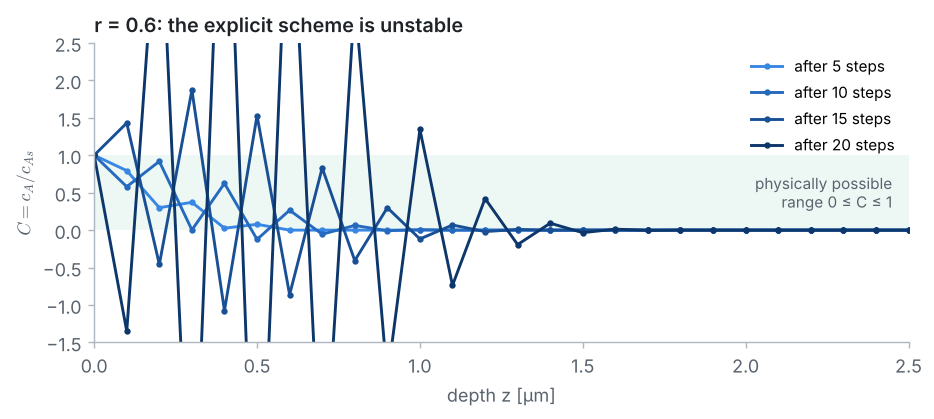

In [20]:
plots.unstable(z, unstable_snapshots, r_bad)

A saw-tooth appears at the surface and grows with every step; concentrations become negative and larger than the surface value, which is physically impossible. The middle weight $1 - 2r = -0.2$ is negative, so each step *amplifies* differences between neighbours instead of smoothing them. **Always check the stability condition of an explicit scheme.**

---
## Summary

* Diffusion of P into Si is described by **Fick's second law**, $\partial c_A/\partial t = D_{AB}\,\partial^2 c_A/\partial z^2$, with one initial and two boundary conditions.
* The **semi-infinite** wafer was cut at $z_{max} = 5$ µm, about ten diffusion lengths, deep enough that the phosphorus never reaches it.
* The **explicit FTCS** scheme turns the PDE into a simple update formula; it is stable only for $r = D\Delta t/\Delta z^2 \le 1/2$.
* After 1 h, the **film depth** (1 % level) is about **1.77 µm** from FDM and **1.76 µm** exactly; the depth grows like $\sqrt{t}$.
* Refining the grid at fixed $r$ divides the error by 4 each time: the code is verified.

## Try it yourself

1. How long must the wafer stay in the reactor for a film **twice as deep** (3.5 µm)? Predict it from the $\sqrt{t}$ law first, then check with the code (you may need a larger `z_max`).
2. Cut the wafer at `z_max = 2` µm instead of 5 µm. What goes wrong, and why?
3. Try `r = 0.5` and `r = 0.51`. Where exactly does the scheme become unstable?
4. Define the film edge at 10 % instead of 1 % of the surface value. How does the depth change?
5. *Challenge:* write the **implicit** (BTCS) version, $-r\,C_{i-1}^{n+1} + (1+2r)\,C_i^{n+1} - r\,C_{i+1}^{n+1} = C_i^n$, and solve it at every step with the **Thomas algorithm** from Problem 1. It is stable for any $\Delta t$: try $\Delta t = 600$ s.